In [1]:
print("Notebook is working!")


Notebook is working!


In [10]:
import os
print(os.listdir())


['.git', '.gitignore', 'hello.py', 'network_flow_regression.ipynb', 'README.md', 'requirements.txt', 'UNSW_NB15_training-set (2).csv', 'venv313']


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All main libraries imported successfully!")

All main libraries imported successfully!


In [13]:
import sys; print(sys.executable)


c:\Users\IDEAPAD\Crypto RTP\venv313\Scripts\python.exe


In [38]:
df = pd.read_csv("UNSW_NB15_training-set (2).csv")
print(df.shape)


(82332, 45)


In [39]:
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [40]:
df.columns.tolist()

['id',
 'dur',
 'proto',
 'service',
 'state',
 'spkts',
 'dpkts',
 'sbytes',
 'dbytes',
 'rate',
 'sttl',
 'dttl',
 'sload',
 'dload',
 'sloss',
 'dloss',
 'sinpkt',
 'dinpkt',
 'sjit',
 'djit',
 'swin',
 'stcpb',
 'dtcpb',
 'dwin',
 'tcprtt',
 'synack',
 'ackdat',
 'smean',
 'dmean',
 'trans_depth',
 'response_body_len',
 'ct_srv_src',
 'ct_state_ttl',
 'ct_dst_ltm',
 'ct_src_dport_ltm',
 'ct_dst_sport_ltm',
 'ct_dst_src_ltm',
 'is_ftp_login',
 'ct_ftp_cmd',
 'ct_flw_http_mthd',
 'ct_src_ltm',
 'ct_srv_dst',
 'is_sm_ips_ports',
 'attack_cat',
 'label']

// WE CAN REMOVE ID ATTACK _CAT AND LABEL IT DOESNT MAKE THAT SENSE THINK OF IT LATER

In [41]:
df.dtypes

id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

We would be ignoring ID as it's just an identifier. Attack cat is, I don't know, label is some label type thing and do DUR is a target so we would be ignoring that.

In [42]:
df.isnull().sum().sort_values(ascending=False)

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [43]:
df.duplicated().sum()


np.int64(0)

In [44]:
df["dur"].describe()

count    82332.000000
mean         1.006756
std          4.710444
min          0.000000
25%          0.000008
50%          0.014138
75%          0.719360
max         59.999989
Name: dur, dtype: float64

In [45]:
df["dur"].skew()


np.float64(9.523750393344962)

The target is highly right-skewed as mean is larger than median

In [46]:
df["dur_log"] = np.log1p(df["dur"])

In [47]:
df["dur_log"].skew()

np.float64(3.2244736955885123)

In [48]:
df["dur_log2"] = np.log1p(df["dur_log"])

In [49]:
df["dur_log2"].skew()

np.float64(1.592079920862152)

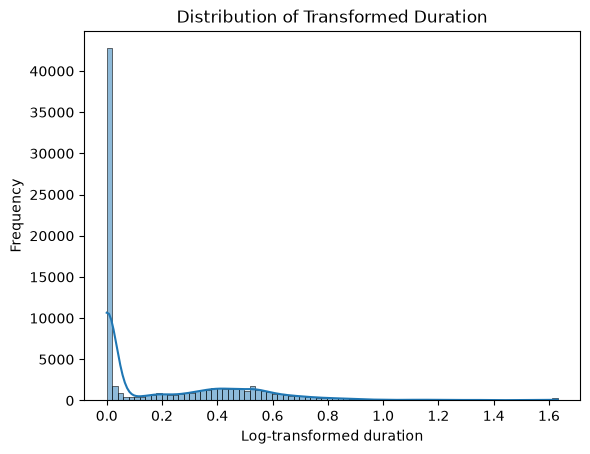

In [50]:
sns.histplot(df["dur_log2"], kde=True)
plt.title("Distribution of Transformed Duration")
plt.xlabel("Log-transformed duration")
plt.ylabel("Frequency")
plt.show()

The transformation made the target more suitable for regression. It reduced the effect of extreme duration values and produced a more balanced distribution, although it did not make the distribution perfectly normal.Also, it shows that most of the deviations are near to zero. 

In [51]:
df.dtypes


id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

In [52]:
df[["proto", "service", "state", "attack_cat"]].nunique()

proto         131
service        13
state           7
attack_cat     10
dtype: int64

These columns contain text, and we needed to identify how many unique values exist in each of these. It's confirmed we won't be using attack categories because it's not relevant to our linear regression. 

In [53]:
df["proto"].value_counts().head(10)


proto
tcp     43095
udp     29418
unas     3515
arp       987
ospf      676
sctp      324
any        96
gre        88
rsvp       64
ipv6       61
Name: count, dtype: int64

In [54]:
df["service"].value_counts()

service
-           47153
dns         21367
http         8287
smtp         1851
ftp          1552
ftp-data     1396
pop3          423
ssh           204
ssl            30
snmp           29
dhcp           26
radius          9
irc             5
Name: count, dtype: int64

In [55]:
df["state"].value_counts()

state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1
Name: count, dtype: int64

In [56]:
df.select_dtypes(include="number").corr()["dur"].sort_values(ascending=False)

dur                  1.000000
dur_log              0.783718
dur_log2             0.610585
spkts                0.280239
sloss                0.240113
sbytes               0.225432
dpkts                0.217507
dbytes               0.172492
dloss                0.171182
djit                 0.165418
dinpkt               0.150801
sjit                 0.146599
ct_state_ttl         0.093925
smean                0.090527
dttl                 0.090048
swin                 0.083990
sinpkt               0.079840
response_body_len    0.076215
tcprtt               0.075329
ackdat               0.073074
synack               0.066530
dwin                 0.061186
dtcpb                0.045306
stcpb                0.044482
dmean                0.043637
is_sm_ips_ports      0.027472
ct_flw_http_mthd     0.018879
id                   0.016037
is_ftp_login         0.015724
ct_ftp_cmd           0.015547
trans_depth          0.006017
sttl                -0.000986
label               -0.001145
dload     

Packet counts, packet loss, and the amount of transferred data have the strongest positive linear relationships with network duration. Traffic rate has a weak negative relationship with duration. Most individual features have weak correlations, indicating that predicting duration will likely require combining multiple numerical and categorical features rather than relying on one variable alone. 

We will determine the actual predictive performance later using R² and RMSE on the test data.

In [63]:
X = df.drop(columns=["id", "dur", "dur_log", "dur_log2", "attack_cat", "label"])
y = df["dur_log2"]

In [64]:
X.shape, y.shape

((82332, 41), (82332,))

In [65]:
categorical_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

In [66]:
categorical_cols, numeric_cols

(['proto', 'service', 'state'],
 ['spkts',
  'dpkts',
  'sbytes',
  'dbytes',
  'rate',
  'sttl',
  'dttl',
  'sload',
  'dload',
  'sloss',
  'dloss',
  'sinpkt',
  'dinpkt',
  'sjit',
  'djit',
  'swin',
  'stcpb',
  'dtcpb',
  'dwin',
  'tcprtt',
  'synack',
  'ackdat',
  'smean',
  'dmean',
  'trans_depth',
  'response_body_len',
  'ct_srv_src',
  'ct_state_ttl',
  'ct_dst_ltm',
  'ct_src_dport_ltm',
  'ct_dst_sport_ltm',
  'ct_dst_src_ltm',
  'is_ftp_login',
  'ct_ftp_cmd',
  'ct_flw_http_mthd',
  'ct_src_ltm',
  'ct_srv_dst',
  'is_sm_ips_ports'])

In [68]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(X))

split_index = int(len(X) * 0.8)
train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]
y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((65865, 41), (16467, 41), (65865,), (16467,))

We randomly divide the dataset into 80% training data and 20% testing data. The model learns patterns from the training data, while the testing data is reserved for evaluating how well the model performs on unseen records.

In [69]:
X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols, dtype=float)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, dtype=float)

This ensures that the test data uses the same feature structure as the training data.

In [70]:
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)
X_train_encoded.shape, X_test_encoded.shape

((65865, 188), (16467, 188))

the training and testing encoded datasets have exactly the same columns.

In [71]:
X_train_array = X_train_encoded.to_numpy(dtype=float)
X_test_array = X_test_encoded.to_numpy(dtype=float)
y_train_array = y_train.to_numpy(dtype=float)
y_test_array = y_test.to_numpy(dtype=float)

we need to convert the pandas DataFrames into NumPy arrays, which will make matrix calculations easier for our regression model.

In [72]:
train_mean = X_train_array.mean(axis=0)
train_std = X_train_array.std(axis=0)

train_std[train_std == 0] = 1

X_train_scaled = (X_train_array - train_mean) / train_std
X_test_scaled = (X_test_array - train_mean) / train_std

"Scaling"-Scaling makes the features numerically comparable, helping gradient descent train more efficiently and preventing large-valued features from overpowering smaller-valued features.

We calculate the mean and standard deviation only from the training data, then use those same values to scale the test data. This prevents test-data information from leaking into training.

In [73]:
X_train_b = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_b = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]

weights = np.zeros(X_train_b.shape[1])

X_train_b.shape, X_test_b.shape, weights.shape

((65865, 189), (16467, 189), (189,))

The intercept b0  allows the model to make predictions even when all feature values are zero.
This adds one column of 1s for the intercept and initializes all model weights to zero *****

In [74]:
def train_linear_regression_gd(X, y, learning_rate=0.01, epochs=500):
    n_samples = X.shape[0]
    weights = np.zeros(X.shape[1])
    losses = []

    for epoch in range(epochs):
        predictions = X @ weights
        errors = predictions - y

        gradient = (2 / n_samples) * (X.T @ errors)
        weights = weights - learning_rate * gradient

        loss = np.mean(errors ** 2)
        losses.append(loss)

    return weights, losses

# Linear Regression Using Gradient Descent

## Full Function

```python
def train_linear_regression_gd(X, y, learning_rate=0.01, epochs=500):
    n_samples = X.shape[0]
    weights = np.zeros(X.shape[1])
    losses = []

    for epoch in range(epochs):
        predictions = X @ weights
        errors = predictions - y

        gradient = (2 / n_samples) * (X.T @ errors)
        weights = weights - learning_rate * gradient

        loss = np.mean(errors ** 2)
        losses.append(loss)

    return weights, losses
```

---

## 1. Defining the Function

```python
def train_linear_regression_gd(X, y, learning_rate=0.01, epochs=500):
```

### `def`

`def` tells Python that we are creating a reusable function.

A function is a named block of code that performs a specific task. Instead of writing the training process repeatedly, we define it once and call it whenever needed.

### Function Name

```python
train_linear_regression_gd
```

The name can be broken into three parts:

- `train` means that the function trains a model.
- `linear_regression` means that the model is linear regression.
- `gd` stands for gradient descent.

Therefore, the function means:

> Train a linear regression model using gradient descent.

### `X`

```python
X
```

`X` contains the input features used to predict the duration of a network connection.

In this project:

- Each row represents one network connection.
- Each column represents a feature.
- Features include packet counts, byte counts, protocol information, and other network-related measurements.

Our training data has the shape:

```python
(65865, 189)
```

This means:

- `65,865` training examples
- `189` feature columns, including the intercept column

### `y`

```python
y
```

`y` contains the correct target values that the model is trying to predict.

Our target is the transformed duration:

```python
dur_log2
```

We use the transformed target because the original duration data was highly skewed.

For training, we use:

```python
y_train_array
```

This contains 65,865 target values.

### `learning_rate=0.01`

```python
learning_rate=0.01
```

The learning rate controls how large each weight update is.

Gradient descent can be imagined as walking downhill toward a point where the error is as small as possible:

- A very large learning rate takes very large steps and may overshoot.
- A very small learning rate takes tiny steps and may train very slowly.
- A reasonable learning rate gradually reduces the error.

In this function, the default learning rate is:

```python
0.01
```

### `epochs=500`

```python
epochs=500
```

An epoch is one complete training iteration.

During each epoch, the model:

1. Makes predictions.
2. Calculates the errors.
3. Calculates the gradient.
4. Updates the weights.
5. Calculates and stores the loss.

The process is repeated 500 times.

---

## 2. Getting the Number of Training Examples

```python
n_samples = X.shape[0]
```

### What is `X.shape`?

For our training data:

```python
X.shape
```

returns:

```python
(65865, 189)
```

The shape is written as:

```text
(number_of_rows, number_of_columns)
```

Therefore:

```python
X.shape[0]
```

gets the number of rows.

So this line:

```python
n_samples = X.shape[0]
```

sets:

```python
n_samples = 65865
```

We need this value when calculating the average gradient across all training examples.

---

## 3. Creating the Initial Weights

```python
weights = np.zeros(X.shape[1])
```

This creates the initial weights for the linear regression model.

### What Are Weights?

Linear regression uses an equation like this:

\[
\hat{y} = w_0 + w_1x_1 + w_2x_2 + \cdots + w_nx_n
\]

Where:

- \(\hat{y}\) is the predicted value.
- \(w_0\) is the intercept.
- \(w_1, w_2, \ldots, w_n\) are feature weights.
- \(x_1, x_2, \ldots, x_n\) are feature values.

Each feature needs its own weight.

For example:

```text
Packet count × its weight
Bytes × its weight
Rate × its weight
Protocol feature × its weight
```

### Why Use `X.shape[1]`?

```python
X.shape[1]
```

gets the number of columns in `X`.

Our training matrix has 189 columns, so this line is equivalent to:

```python
weights = np.zeros(189)
```

The result is an array containing 189 zeros:

```python
[0., 0., 0., 0., 0., ...]
```

The model initially knows nothing, so all weights start at zero.

---

## 4. Creating a List to Store the Loss

```python
losses = []
```

This creates an empty Python list.

During training, we want to track how much error the model has after each epoch.

For example, the list may eventually look like:

```python
[
    0.85,
    0.72,
    0.64,
    0.58,
    ...
]
```

Each value represents the model's error at a particular training step.

We will later use this list to create a learning curve showing whether the model is improving.

---

## 5. Starting the Training Loop

```python
for epoch in range(epochs):
```

Since:

```python
epochs = 500
```

this means:

```python
for epoch in range(500):
```

Python repeats the indented code 500 times.

The variable `epoch` represents the current iteration number.

It will take values such as:

```text
0
1
2
3
...
499
```

Each loop performs one complete weight-update cycle.

---

## 6. Making Predictions

```python
predictions = X @ weights
```

This is the main prediction calculation.

### What Does `@` Mean?

In NumPy, `@` means matrix multiplication.

It multiplies the feature matrix by the weight vector.

Mathematically:

\[
\hat{y} = Xw
\]

For one row, the calculation is conceptually:

\[
\hat{y}
=
w_0(1)
+
w_1x_1
+
w_2x_2
+
\cdots
+
w_{188}x_{188}
\]

Because we added a column of ones earlier, the first weight acts as the intercept.

### Matrix Shapes

Our data has these shapes:

```text
X       → (65865, 189)
weights → (189,)
```

Matrix multiplication produces:

```text
predictions → (65865,)
```

This means the model creates one predicted duration value for every training example.

At the beginning, all weights are zero, so the initial predictions are close to zero. After the weights are updated, the predictions become more meaningful.

---

## 7. Calculating the Errors

```python
errors = predictions - y
```

This compares the model's predictions with the correct target values.

The formula is:

\[
\text{error} = \text{prediction} - \text{actual value}
\]

For example:

```text
Predicted value: 0.8
Actual value:    1.0
Error:          -0.2
```

Another example:

```text
Predicted value: 1.4
Actual value:    1.0
Error:            0.4
```

The error can be:

- Negative: the model predicted too low.
- Positive: the model predicted too high.
- Zero: the model predicted exactly correctly.

Because there are 65,865 training examples, `errors` contains 65,865 error values.

---

## 8. Calculating the Gradient

```python
gradient = (2 / n_samples) * (X.T @ errors)
```

This is the most mathematical line in the function.

The gradient tells us:

> For each weight, which direction should it move to reduce the prediction error?

The line can be understood in smaller pieces.

### 8.1 Transposing `X`

```python
X.T
```

The `.T` means transpose.

Transposing switches the rows and columns.

Before transposing:

```text
X shape = (65865, 189)
```

After transposing:

```text
X.T shape = (189, 65865)
```

We need the transpose so that the matrix multiplication can calculate one gradient value for each of the 189 weights.

---

### 8.2 Calculating `X.T @ errors`

```python
X.T @ errors
```

This combines:

- The feature values
- The prediction errors

It calculates how strongly each feature is related to the model's current errors.

The result contains one gradient value for each feature:

```text
Gradient for intercept
Gradient for spkts
Gradient for dpkts
Gradient for sbytes
Gradient for dbytes
...
```

The result has the shape:

```text
(189,)
```

A large positive or negative gradient means the corresponding weight needs a stronger adjustment.

A gradient close to zero means that the corresponding weight may not need much adjustment.

---

### 8.3 Multiplying by `2 / n_samples`

```python
(2 / n_samples)
```

This averages the gradient over all training examples and includes the factor of 2 that comes from differentiating the squared-error function.

The mean squared error is:

\[
\text{MSE}
=
\frac{1}{n}
\sum_{i=1}^{n}
(\hat{y}_i-y_i)^2
\]

When the squared error is differentiated, the factor `2` appears.

Therefore:

```python
(2 / n_samples)
```

makes the gradient correspond to the mean squared error.

---

## 9. Updating the Weights

```python
weights = weights - learning_rate * gradient
```

This is the actual learning step.

The mathematical formula is:

\[
w_{\text{new}}
=
w_{\text{old}}
-
\alpha \nabla J(w)
\]

Where:

- \(w\) is the weight vector.
- \(\alpha\) is the learning rate.
- \(\nabla J(w)\) is the gradient.
- \(J(w)\) is the loss function.

In Python:

```python
weights = weights - learning_rate * gradient
```

### Why Do We Subtract the Gradient?

The gradient points in the direction where the error increases.

We want to move in the opposite direction to reduce the error.

That is why the gradient is subtracted.

### Example

Suppose:

```python
weight = 0.2
learning_rate = 0.01
gradient = 5
```

The new weight would be:

```python
new_weight = 0.2 - (0.01 * 5)
```

Result:

```python
new_weight = 0.15
```

The weight decreases.

If the gradient were negative:

```python
new_weight = 0.2 - (0.01 * -5)
```

Result:

```python
new_weight = 0.25
```

The weight increases.

Therefore, the gradient determines:

- The direction of the update.
- The size of the update.

---

## 10. Calculating the Loss

```python
loss = np.mean(errors ** 2)
```

This calculates the mean squared error, also called MSE.

### `errors ** 2`

This squares every error.

For example:

```text
Errors:  [-2, 1, -3]
Squared: [4, 1, 9]
```

Squaring is useful because:

- Negative and positive errors do not cancel each other out.
- Larger mistakes receive a larger penalty.

### `np.mean(...)`

`np.mean()` calculates the average.

Therefore:

```python
np.mean(errors ** 2)
```

means:

> Square every error, then calculate the average.

The formula is:

\[
\text{MSE}
=
\frac{1}{n}
\sum_{i=1}^{n}
(\hat{y}_i-y_i)^2
\]

A lower loss means the predictions are generally closer to the actual target values.

---

## 11. Saving the Loss

```python
losses.append(loss)
```

This adds the current loss to the `losses` list.

After the first epoch:

```python
losses = [first_loss]
```

After the second epoch:

```python
losses = [first_loss, second_loss]
```

After 500 epochs, the list should contain approximately 500 loss values.

We can later plot the list to see how the model's error changes during training.

If training is working properly, the loss curve should generally decrease.

---

## 12. Returning the Results

```python
return weights, losses
```

Once the training loop finishes, the function returns two values.

### `weights`

These are the trained model parameters.

They contain:

- The learned intercept.
- The learned coefficient for every feature.

### `losses`

This contains the training loss recorded after each epoch.

We can use it to evaluate whether the model learned successfully and to plot the learning curve.

---

## Overall Training Process

The function follows this process:

```text
Start with weights
        ↓
Make predictions
        ↓
Calculate errors
        ↓
Calculate gradient
        ↓
Update weights
        ↓
Calculate loss
        ↓
Save loss
        ↓
Repeat 500 times
```

In simple terms:

> The model repeatedly makes predictions, measures how wrong those predictions are, and adjusts its weights to make better predictions.

In [76]:
weights, losses = train_linear_regression_gd(
    X_train_b,
    y_train_array
)
len(weights), len(losses), losses[:5], losses[-5:]

(189,
 500,
 [np.float64(0.15244468243082462),
  np.float64(0.13223412954153),
  np.float64(0.11934109268011513),
  np.float64(0.11061685730988698),
  np.float64(0.10430692979575258)],
 [np.float64(0.030353359031969143),
  np.float64(0.03035123311992038),
  np.float64(0.030349111915699476),
  np.float64(0.030346995392194074),
  np.float64(0.03034488352251845)])

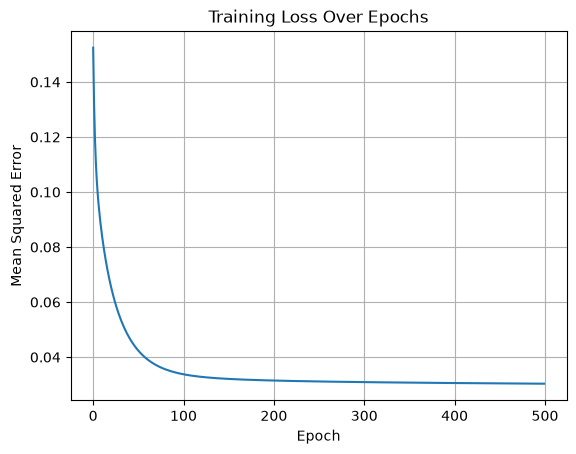

In [77]:
plt.plot(losses)
plt.title("Training Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()

The training loss decreased rapidly during the initial epochs and gradually stabilized as the number of epochs increased. The loss reduced from approximately 0.15 to 0.03, indicating that gradient descent successfully learned the model parameters and reduced prediction error.

In [78]:
y_pred = X_test_b @ weights

This uses the trained weights to predict the transformed duration for the test set.

In [79]:
test_errors = y_pred - y_test_array
test_mse = np.mean(test_errors ** 2)
test_rmse = np.sqrt(test_mse)

test_mse, test_rmse

(np.float64(0.030739683800979356), np.float64(0.17532736181491854))

In [80]:
ss_res = np.sum((y_test_array - y_pred) ** 2)
ss_tot = np.sum((y_test_array - np.mean(y_test_array)) ** 2)

r2_score_manual = 1 - (ss_res / ss_tot)

r2_score_manual

np.float64(0.6903848810342155)

The manually calculated R² score was approximately 0.6904. This indicates that the regression model explains about 69.04% of the variation in the log-transformed duration values on the test dataset

In [81]:
print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)
print("Test R²:", r2_score_manual)

Test MSE: 0.030739683800979356
Test RMSE: 0.17532736181491854
Test R²: 0.6903848810342155


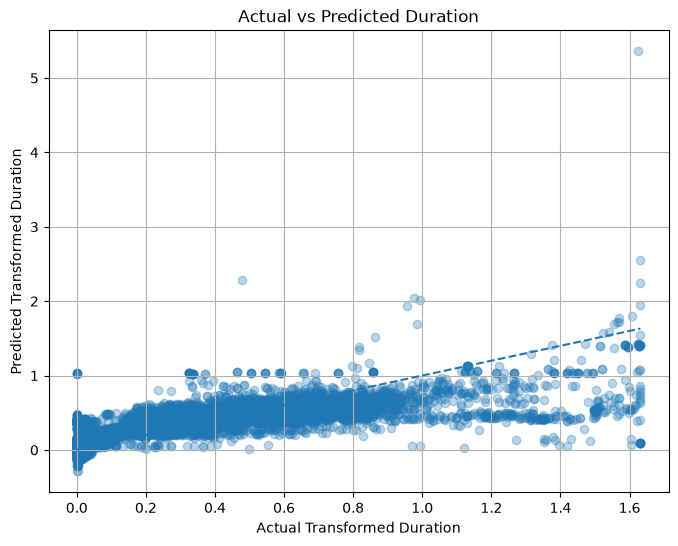

In [82]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_array, y_pred, alpha=0.3)

plt.plot(
    [y_test_array.min(), y_test_array.max()],
    [y_test_array.min(), y_test_array.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Duration")
plt.xlabel("Actual Transformed Duration")
plt.ylabel("Predicted Transformed Duration")
plt.grid(True)
plt.show()

The actual-versus-predicted plot shows a generally positive relationship between the actual and predicted transformed duration values. Most observations are concentrated at lower duration values, reflecting the distribution of the dataset. Although several predictions are close to the ideal diagonal line, the spread of points indicates prediction errors, particularly for some higher-duration connections. This suggests that the model captures the overall trend but does not perfectly model all network connection behaviors.

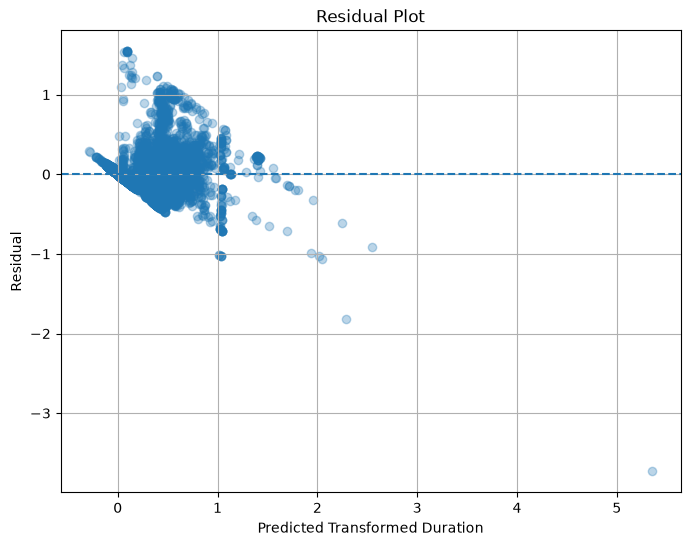

In [83]:
residuals = y_test_array - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Transformed Duration")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

Residual=Actual Value−Predicted Value
The residual plot shows that most residuals are concentrated around zero, indicating that many predictions are relatively close to the actual transformed duration values. However, the residuals are not perfectly randomly distributed, and the spread of errors varies across predicted values. Several outliers are also visible, particularly at higher predicted durations. This suggests that the linear regression model captures the general relationship but may not fully represent the more complex patterns in network connection duration

In [84]:
np.save("linear_regression_weights.npy", weights)
np.save("linear_regression_losses.npy", np.array(losses))